# 00 · Baseline: FinBERT on Twitter Financial News
**AI & Vis UE — Phase I (black box) · AI-aided pair: Dharmik & Sarang**

This notebook produces the shared starting point for Phase I:
1. Load the dataset and FinBERT, and **align the labels by name** (not by index).
2. Run predictions and save a results table (`results_<split>.csv`) with the three softmax scores.
3. Baseline views: confusion matrix, confidence for correct vs. wrong, confidently wrong tweets.
4. First slices (tickers, URLs, numbers, length) to find where errors concentrate.
5. Optional: 2D map of the tweets for spotting error clusters.

**Phase I rule:** only inputs, outputs and softmax scores from FinBERT. No attention, gradients or FinBERT embeddings here (those are Phase II).

Runs on free Colab. Use *Runtime → Change runtime type → T4 GPU* for speed (CPU also works, ~5–10 min for the validation split).

In [ ]:
!pip -q install transformers datasets sentence-transformers umap-learn plotly

In [1]:
import re, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SPLIT = "validation"   # main analysis split (2.4k tweets). "train" (9.5k) also works for bigger slices.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cuda


## 1 · Load data and model, align labels

In [2]:
ds = load_dataset("zeroshot/twitter-financial-news-sentiment")
df = ds[SPLIT].to_pandas()
DATA_LABELS = {0: "Bearish", 1: "Bullish", 2: "Neutral"}   # from the dataset card
df["true"] = df["label"].map(DATA_LABELS)
print(df.shape); print(df["true"].value_counts())

README.md:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

sent_train.csv:   0%|          | 0.00/859k [00:00<?, ?B/s]

sent_valid.csv:   0%|          | 0.00/217k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9543 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2388 [00:00<?, ? examples/s]

(2388, 3)
true
Neutral    1566
Bullish     475
Bearish     347
Name: count, dtype: int64


In [3]:
tok = AutoTokenizer.from_pretrained("ProsusAI/finbert")
model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").to(DEVICE).eval()
id2label = {int(k): v.lower() for k, v in model.config.id2label.items()}
print("FinBERT id2label:", id2label)

# Map by NAME so index order can never cause fake errors
FINBERT_TO_DATA = {"negative": "Bearish", "positive": "Bullish", "neutral": "Neutral"}
assert set(id2label.values()) == set(FINBERT_TO_DATA), "Unexpected FinBERT labels, check config!"

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT id2label: {0: 'positive', 1: 'negative', 2: 'neutral'}


## 2 · Predict and save the results table

In [4]:
@torch.no_grad()
def predict(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i+bs], padding=True, truncation=True, max_length=128, return_tensors="pt").to(DEVICE)
        out.append(torch.softmax(model(**enc).logits, -1).cpu().numpy())
    return np.vstack(out)

probs = predict(df["text"].tolist())
for idx, name in id2label.items():
    df[f"p_{FINBERT_TO_DATA[name].lower()}"] = probs[:, idx]

P = ["p_bearish", "p_bullish", "p_neutral"]
df["pred"] = df[P].idxmax(axis=1).str[2:].str.capitalize()
df["confidence"] = df[P].max(axis=1)
df["correct"] = df["pred"] == df["true"]
df.to_csv(f"results_{SPLIT}.csv", index=False)
df.head()

,text,label,true,p_bullish,p_bearish,p_neutral,pred,confidence,correct
0,$ALLY - Ally Financial pulls outlook https://t...,0,Bearish,0.067915,0.065768,0.866317,Neutral,0.866317,False
1,"$DELL $HPE - Dell, HPE targets trimmed on comp...",0,Bearish,0.270823,0.701612,0.027565,Bearish,0.701612,True
2,$PRTY - Moody's turns negative on Party City h...,0,Bearish,0.009183,0.927084,0.063733,Bearish,0.927084,True
3,$SAN: Deutsche Bank cuts to Hold,0,Bearish,0.146574,0.578625,0.274801,Bearish,0.578625,True
4,$SITC: Compass Point cuts to Sell,0,Bearish,0.309749,0.514394,0.175856,Bearish,0.514394,True


## 3 · Baseline views
A score table is **not** a Phase I result. These views are only the starting point for finding systematic behavior.

Accuracy: 0.725

              precision    recall  f1-score   support

     Bearish      0.493     0.761     0.599       347
     Neutral      0.853     0.756     0.802      1566
     Bullish      0.611     0.598     0.604       475

    accuracy                          0.725      2388
   macro avg      0.652     0.705     0.668      2388
weighted avg      0.753     0.725     0.733      2388



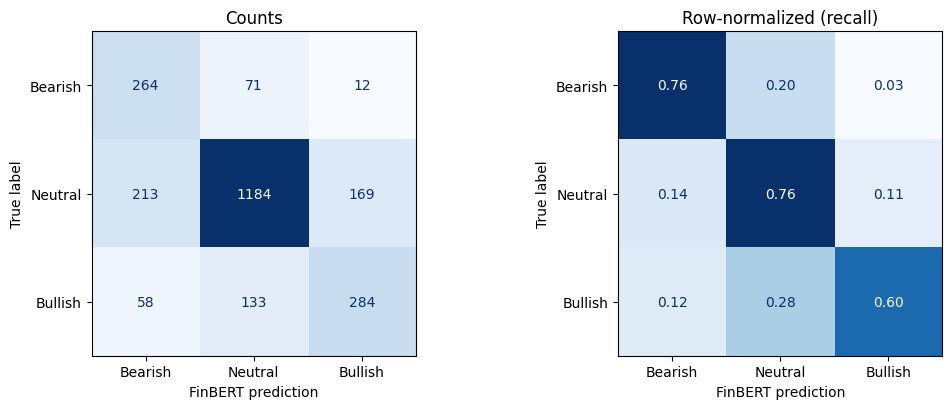

In [5]:
ORDER = ["Bearish", "Neutral", "Bullish"]
print(f"Accuracy: {df['correct'].mean():.3f}\n")
print(classification_report(df["true"], df["pred"], labels=ORDER, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, norm, title in [(axes[0], None, "Counts"), (axes[1], "true", "Row-normalized (recall)")]:
    cm = confusion_matrix(df["true"], df["pred"], labels=ORDER, normalize=norm)
    ConfusionMatrixDisplay(cm, display_labels=ORDER).plot(ax=ax, cmap="Blues", colorbar=False,
                                                          values_format=".2f" if norm else "d")
    ax.set_title(title); ax.set_xlabel("FinBERT prediction"); ax.set_ylabel("True label")
plt.tight_layout(); plt.show()

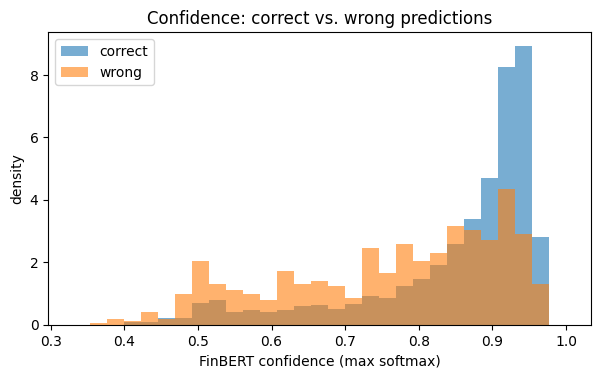

656 errors, 145 of them with confidence > 0.9


In [6]:
# Is the model confidently wrong?
fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(0.33, 1, 30)
ax.hist(df.loc[df.correct, "confidence"], bins=bins, alpha=.6, label="correct", density=True)
ax.hist(df.loc[~df.correct, "confidence"], bins=bins, alpha=.6, label="wrong", density=True)
ax.set_xlabel("FinBERT confidence (max softmax)"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Confidence: correct vs. wrong predictions"); plt.show()

wrong = df[~df.correct]
print(f"{len(wrong)} errors, {(wrong.confidence > .9).sum()} of them with confidence > 0.9")

In [7]:
# Most confidently wrong tweets: read these, they are where hypotheses come from
pd.set_option("display.max_colwidth", 140)
wrong.sort_values("confidence", ascending=False)[["text", "true", "pred", "confidence"]].head(25)

,text,true,pred,confidence
928,SoftBank's Oyo reveals over $330 million annual loss; revenue surges https://t.co/sboVq3nnEm https://t.co/FNiIij62NJ,Neutral,Bearish,0.973669
258,$ITRN - Margins suffer at Ituran Location in Q3 https://t.co/cCI94Csl3s,Neutral,Bearish,0.973663
1623,Saudi Arabia's Unemployment Falls to Lowest in Over Three Years,Bullish,Bearish,0.972324
1755,Dow Jones News: Apple Production Problems; Boeing Upgraded,Neutral,Bearish,0.967583
1769,UPDATE 2-European stocks end flat as defensive gains offset auto slide,Neutral,Bearish,0.966285
2201,Should CorEnergy Infrastructure Trust (NYSE:CORR) Be Disappointed With Their 39% Profit?,Neutral,Bearish,0.964911
1118,EY has put 100 jobs in its financial consulting unit at risk of redundancy\nhttps://t.co/d63wR7xMfR,Neutral,Bearish,0.964294
2365,"Tesla Tops $900 in Parabolic Surge, Spurring Analyst Downgrade",Bullish,Bearish,0.963861
282,Activision Blizzard’s Revenue To See Double-Digit Decline In 2019?,Neutral,Bearish,0.963544
783,Lumber futures rally as producers cut output https://t.co/WsTaphOfvv,Bullish,Bearish,0.963011


## 4 · First slices: where do errors concentrate?

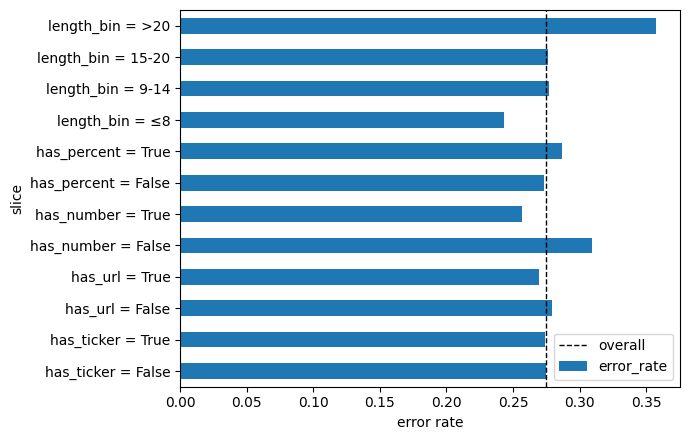

,slice,n,acc,error_rate
0,has_ticker = False,2020,0.725248,0.274752
1,has_ticker = True,368,0.725543,0.274457
0,has_url = False,1246,0.720706,0.279294
1,has_url = True,1142,0.730298,0.269702
0,has_number = False,825,0.690909,0.309091
1,has_number = True,1563,0.743442,0.256558
0,has_percent = False,2158,0.726599,0.273401
1,has_percent = True,230,0.713043,0.286957
0,length_bin = ≤8,506,0.756917,0.243083
1,length_bin = 9-14,1177,0.723025,0.276975


In [8]:
df["has_ticker"]  = df.text.str.contains(r"\$[A-Za-z]{1,5}\b")
df["has_url"]     = df.text.str.contains(r"https?://")
df["has_number"]  = df.text.str.contains(r"\d")
df["has_percent"] = df.text.str.contains(r"%")
df["n_words"]     = df.text.str.split().str.len()
df["length_bin"]  = pd.cut(df.n_words, [0, 8, 14, 20, 100], labels=["≤8", "9-14", "15-20", ">20"])

rows = []
for col in ["has_ticker", "has_url", "has_number", "has_percent", "length_bin"]:
    g = df.groupby(col, observed=True)["correct"].agg(n="size", acc="mean").reset_index()
    g["slice"] = col + " = " + g[col].astype(str)
    rows.append(g[["slice", "n", "acc"]])
slices = pd.concat(rows)
slices["error_rate"] = 1 - slices["acc"]

ax = slices.set_index("slice")["error_rate"].plot.barh(figsize=(7, 4.5))
ax.axvline(1 - df.correct.mean(), ls="--", c="k", lw=1, label="overall")
ax.set_xlabel("error rate"); ax.legend(); plt.tight_layout(); plt.show()
slices

In [9]:
# Error rate per true class within each slice (are errors class-specific?)
pd.crosstab([df.has_ticker, df.has_url], df.true, values=~df.correct, aggfunc="mean").round(3)

true                Bearish  Bullish  Neutral
has_ticker has_url                           
False      False      0.243    0.328    0.262
           True       0.237    0.473    0.255
True       False      0.400    0.583    0.250
           True       0.209    0.480    0.132

## 5 · (Optional) 2D map of tweets
Embeddings come from a **separate sentence encoder**, not FinBERT, so this stays black-box with respect to FinBERT.
(Confirm with the instructors at Feedback 1 that this counts as Phase I.)
Hover over points to read tweets and look for clusters with many errors.

In [10]:
from sentence_transformers import SentenceTransformer
import umap, plotly.express as px

enc = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
emb = enc.encode(df.text.tolist(), batch_size=128, show_progress_bar=True)
xy = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42).fit_transform(emb)
df["x"], df["y"] = xy[:, 0], xy[:, 1]
df["outcome"] = np.where(df.correct, "correct", "wrong: " + df.true + "→" + df.pred)

fig = px.scatter(df, x="x", y="y", color="outcome", hover_data={"text": True, "confidence": ":.2f", "x": False, "y": False},
                 opacity=.7, height=650, title="Tweets (MiniLM + UMAP), colored by FinBERT outcome")
fig.update_traces(marker_size=5); fig.show()
df.to_csv(f"results_{SPLIT}.csv", index=False)   # re-save with features + coordinates

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/19 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Bring to the group meeting
- Accuracy and the confusion matrix: which class pair is confused most?
- Is FinBERT **confidently wrong**? How many errors have confidence > 0.9?
- 3–5 example tweets from the confidently-wrong list, and your guess at *why*
- Any slice with a clearly higher error rate
- Proposal for 2–3 shared Phase I questions